# 연구 틀
이 파일을 복사해서 쓴다(예: `연구_홍길동_GPA저변동.ipynb`). **[바꾸는 칸]**이라고 적힌 칸(0·1·3·4)만 고치고, **[건드리지 않는 칸]**은 그대로 둔다.
돌린 실험은 9번 칸이 `연구/결과/`에 자동으로 남긴다(지우지 않는다).

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 0. 실험 기록 [바꾸는 칸]
누가, 언제, 무엇을 왜 바꾸는지 적는다. 저장 파일 이름(이름_날짜_실험명.csv)에 쓰인다.

In [1]:
실험 = dict(
    이름="연구자이름",
    날짜="2026-11-01",
    실험명="예시_GPA_EY_저변동성",
    무엇을="우동호 IMF(GP/A+EY)에 저변동성을 셋째 지표로 더함",
    왜="수익성·가치에 위험을 더하면 MDD(최대 낙폭)가 줄어드는지 보려고",
)

## 1. 데이터 경로 [바꾸는 칸]
기본은 새로 통째로 받은 파일(`data\통합_전체_202611`)이다.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import 데이터읽기 as 읽기
print(읽기.DATA)

D:\26-2_데이터기반투자전략\과제02\data\통합_202611


## 2. 공통 불러오기 [건드리지 않는 칸]

In [3]:
import json
import pandas as pd
import 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

## 3. 설정 [바꾸는 칸]
`포.기본설정`에서 바꿀 것만 적는다. 쓸 수 있는 값:
- 시장: `"KS"`(유가증권), `"KQ"`(코스닥) / 기준일: `"첫거래일"`, `"마지막거래일"` / 리밸런싱: 1·3·12(달)
- 제외: `종목거르기.py`의 함수 이름 — 보통주, 스팩, 금융업, 투자기구, 결산월, 거래정지, 관리종목, 동전주, 자본잠식, 회전율, 거래대금, 시총상위, 시총분위, 종목빼기 (옵션은 `("이름", {옵션})`). `시장`과 `쓰지말것`(README_데이터 '쓰지 말 것' 구간)은 항상 먼저 적용된다
- 지표와 방향: `지표.py`의 함수 이름 + `"높게"`/`"낮게"` (단계별이면 셋째 값 = 남길 비율)
- 합산: `"순위합산"`, `"z합산"`, `"단계별"` / 고르기: `("상위N", n)`, `("분위", k)`
- 재무시점: `("결산후개월", k)`(결산일 + k개월, 발표일 안 봄) | `("발표일", k)`(발표일 다음 거래일, 없으면 결산일 + k일. k = 150 본문, 180 확인)
- 여러 전략 한 번에: `"전략들": {이름: dict(지표=..., 합산=...)}`(확장연구 노트북 참고)
- 비중: `"동일"`, `"시총"`, `"시총상한"`(비중상한), `"시총상한10"`·`"시총상한30"`, `"위험균형"`(직전 12개월 변동성 역수), `"최소분산"`(공매도 없음, 직전 36개월 월수익률, Ledoit-Wolf 수축) / 거래비용: 수수료·거래세·슬리피지(·월비용) / 전량교체: `True`면 리밸런싱 때 전부 팔고 새로 삼(우동호 원문), `False`면 바뀐 만큼만

In [4]:
설정 = {**포.기본설정,
    "이름": 실험["실험명"],
    "시장": ["KS", "KQ"],
    "기간": ("1990-01", "2026-09"),  # 백테스트 시작 1990-01(배당 포함 수정주가 S410007700은 1990년부터 값 있음, 1988~89는 0종목)
    "기준일": "첫거래일",
    "리밸런싱": 12,
    "재무시점": ("발표일", 150),  # 1999년 이전은 발표일 기록이 거의 없어 결산일 + 150일(통합_확인기록 F8)
    "제외": ["보통주", "금융업", "투자기구", ("결산월", {"월": 12}), "거래정지"],
    "지표": [("GPA", "높게"), ("EY", "높게"), ("저변동_예시", "높게")],
    "합산": "순위합산",
    "고르기": ("상위N", 30),
    "비중": ["동일", "시총"],
    "거래비용": dict(수수료=0.00015, 거래세=0.0025, 슬리피지=0.005),
}

## 4. 새 지표 만들기 [바꾸는 칸]
함수 하나를 만들고 `지표` 모듈에 붙이면 설정의 `지표`에서 이름으로 쓸 수 있다. 입력 `s`의 내용은 `공통/지표.py` 맨 위 설명 참고.
아래 예시는 변동성의 음수(높을수록 덜 출렁임)다. 새 지표를 계속 쓸 거면 `공통/지표.py`에 옮기고 README의 변경 기록에 적는다.

In [5]:
def 저변동_예시(s):
    """직전 12개월 일간수익률 표준편차의 음수."""
    return -지표.변동성(s)

지표.저변동_예시 = 저변동_예시

## 5. 실행 [건드리지 않는 칸]

In [6]:
결과 = 포.실행(설정)
F = 평가.요인(포.기준일(결과["설정"]), 결과["설정"])
R = pd.DataFrame({f"{b}_{g}": 결과["수익률"][(b, g)] for b, g in 결과["수익률"]})
if 설정["고르기"][0] == "분위":  # LS는 거래비용 0으로 다시 돌려 만든다(비용 뺀 Q5를 빼면 숏 쪽 비용 부호가 거꾸로 됨)
    g = 포.실행({**설정, "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)})["수익률"]
    for b in 설정["비중"]:
        R[f"{b}_LS(비용0)"] = g[(b, "Q1")] - g[(b, f"Q{설정['고르기'][1]}")]
R["시장"] = F["시장"]
R = R.dropna(how="all")

## 6. 결과표·누적수익률 그림 [건드리지 않는 칸]

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW)
동일_상위30,428.0000,193.9434,0.1593,0.3073,0.4375,-0.6746,0.3266,0.0112,2.6126,2.1554,0.0089,2.4719,2.2699,0.0089,2.7554,1.8020,0.0091,2.8004,1.6786
시총_상위30,428.0000,91.5639,0.1354,0.2715,0.3947,-0.6477,0.2851,0.0090,2.3571,2.1392,0.0065,2.2751,2.1853,0.0058,2.0338,1.7826,0.0053,1.8713,1.6034
시장,440.0000,6.5235,0.0566,0.2690,0.1212,-0.7243,NaN,0.0027,0.7337,0.6659,-0.0000,-1.0548,-0.9830,0.0000,20.4139,8.4696,0.0000,20.2906,8.4753


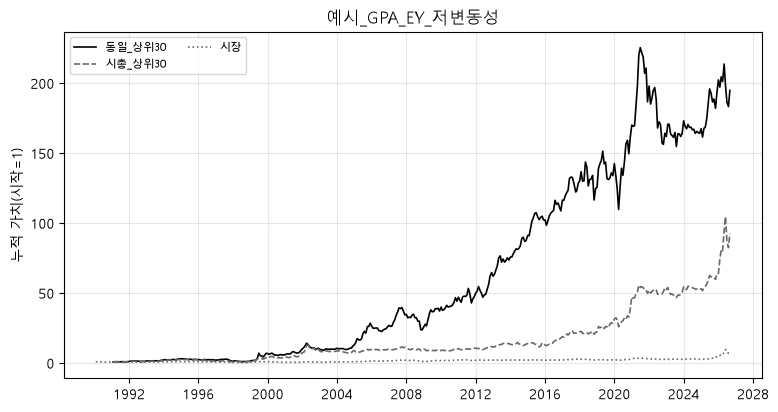

In [7]:
표 = 평가.성과표(R, F, [c for c in R if "_LS" in c])
평가.누적그림(R, 설정["이름"]);
표

## 7. 같은 기간 기준과 자동 비교 [건드리지 않는 칸]
같은 기간으로 우동호(2023) 재현과 시장을 돌려 나란히 놓는다. 무위험이자율과 전량교체 여부는 3번 칸 설정 것을 쓴다.
기준은 두 줄이다. **본문 설정**은 우동호 그대로(배당 빠진 수정주가, 결산 후 3개월), **같은 가격·재무시점**은 가격 계열과 재무시점까지 3번 칸 설정에 맞춘 것. 두 기준의 차이는 배당 포함 여부와 재무시점 차이에서 나온다. 실험 효과는 '같은 가격·재무시점' 줄과 비교한다.
기간 안에서 개월 수가 다를 수 있다(개월 칸 확인. 첫 리밸런싱에 종목이 없으면 그 구간은 빈칸).

In [8]:
기준 = {**포.우동호2023, "기간": 설정["기간"], "무위험": 설정["무위험"], "전량교체": 설정["전량교체"]}
기준들 = {f"기준:{기준['이름']}(본문 설정)": 기준, f"기준:{기준['이름']}(같은 가격·재무시점)": {**기준, "가격": 설정["가격"], "재무시점": 설정["재무시점"]}}
Fb = 평가.요인(포.기준일(기준), 기준)
기준표 = 평가.성과표(pd.DataFrame({k: 포.실행(v)["수익률"][("동일", "상위30")] for k, v in 기준들.items()} | {"기준:시장": Fb["시장"]}).dropna(how="all"), Fb)
비교 = pd.concat([표, 기준표])
비교[["개월", "누적", "연환산", "표준편차(연)", "샤프", "MDD", "정보비율", "Carhart α(월)", "Carhart t(NW)"]]

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,Carhart α(월),Carhart t(NW)
동일_상위30,428.0000,193.9434,0.1593,0.3073,0.4375,-0.6746,0.3266,0.0091,1.6786
시총_상위30,428.0000,91.5639,0.1354,0.2715,0.3947,-0.6477,0.2851,0.0053,1.6034
시장,440.0000,6.5235,0.0566,0.2690,0.1212,-0.7243,NaN,0.0000,8.4753
기준:우동호2023_MF(본문 설정),440.0000,14.0236,0.0767,0.3306,0.2028,-0.6578,0.1226,0.0047,1.0328
기준:우동호2023_MF(같은 가격·재무시점),440.0000,26.4114,0.0945,0.3304,0.2524,-0.6401,0.1817,0.0061,1.3405
기준:시장,440.0000,6.5235,0.0566,0.2690,0.1212,-0.7243,NaN,0.0000,8.4753


## 8. 확인 [건드리지 않는 칸]
리밸런싱마다 단계별 남은 종목 수, 지표별 빈칸 수, 빈칸 때문에 빠진 수, 편입 수.

In [9]:
결과["기록"].T

기준일,1990-01-03,1991-01-03,1992-01-03,1993-01-04,1994-01-03,1995-01-03,1996-01-03,1997-01-03,1998-01-03,1999-01-04,...,2017-01-02,2018-01-02,2019-01-02,2020-01-02,2021-01-04,2022-01-03,2023-01-02,2024-01-02,2025-01-02,2026-01-02
가격있음,590,627,644,647,655,686,714,1083,1132,1075,...,1979,2034,2103,2197,2263,2350,2432,2536,2624,2670
시장,590,627,644,647,655,686,714,1083,1132,1075,...,1979,2034,2103,2197,2263,2350,2432,2536,2624,2670
쓰지말것,590,627,644,647,655,686,714,1083,1132,1075,...,1970,2034,2103,2193,2263,2347,2430,2536,2623,2666
보통주,590,627,644,647,655,686,714,1082,1132,1075,...,1970,2034,2103,2193,2263,2347,2430,2536,2623,2666
금융업,506,541,558,560,568,594,619,933,988,950,...,1843,1836,1905,2016,2081,2162,2224,2320,2383,2441
투자기구,506,541,558,560,568,594,619,933,988,950,...,1828,1826,1893,2005,2065,2143,2203,2297,2360,2420
결산월,419,451,468,472,482,507,532,820,871,837,...,1786,1772,1851,1957,2021,2100,2163,2251,2324,2386
거래정지,419,451,468,472,482,507,532,819,868,835,...,1770,1751,1822,1900,1942,2022,2104,2182,2240,2297
빈칸:GPA,5,4,1,5,10,10,12,88,67,48,...,3,2,2,5,8,10,4,5,9,5
빈칸:EY,7,6,3,7,12,11,13,93,74,52,...,102,124,128,137,21,15,14,15,24,25


## 9. 저장 [건드리지 않는 칸]
설정과 결과를 `연구/결과/이름_날짜_실험명.csv`에 남긴다. 같은 이름이 있으면 뒤에 번호를 붙인다(덮어쓰지 않음).

In [10]:
out = Path.cwd() / "결과"
f = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}.csv"
i = 1
while f.exists():
    f, i = out / f"{실험['이름']}_{실험['날짜']}_{실험['실험명']}_{i}.csv", i + 1
비교.assign(실험기록=json.dumps(실험, ensure_ascii=False), 설정=json.dumps(설정, ensure_ascii=False, default=str)).to_csv(f, encoding="utf-8-sig")
print("저장:", f)

저장: D:\26-2_데이터기반투자전략\과제02\과제02_백테스트\연구\결과\연구자이름_2026-11-01_예시_GPA_EY_저변동성_2.csv
